# Bài toán XOR và lan truyền xuôi

*Bài 9, mục 9.1.2.* Hàm XOR không tách được tuyến tính nên một Perceptron (Bài 4) không giải được. Mạng có một lớp ẩn giải được.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Perceptron

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([0, 1, 1, 0])                   # XOR

## 1. Perceptron một lớp thất bại

In [2]:
perceptron = Perceptron(max_iter=1000, random_state=0).fit(X, y)
print('Dự đoán của Perceptron:', perceptron.predict(X), ' nhãn thật:', y)
print('Độ chính xác: %.2f' % perceptron.score(X, y))

Dự đoán của Perceptron: [0 0 0 0]  nhãn thật: [0 1 1 0]
Độ chính xác: 0.50


Mọi đường thẳng chỉ phân loại đúng tối đa 3/4 điểm.

## 2. Mạng 2 – 2 – 1 với trọng số chọn tay

Dùng hàm bước $f(z) = 1$ nếu $z \ge 0$, ngược lại 0.
- Nơ-ron ẩn 1 tính OR: $h_1 = f(x_1 + x_2 - 0.5)$.
- Nơ-ron ẩn 2 tính AND: $h_2 = f(x_1 + x_2 - 1.5)$.
- Nơ-ron ra tính "OR nhưng không AND": $\hat{y} = f(h_1 - h_2 - 0.5)$.

In [3]:
def step(z):
    return (z >= 0).astype(float)


W1 = np.array([[1.0, 1.0],                   # trọng số nơ-ron ẩn 1 (OR)
               [1.0, 1.0]])                  # trọng số nơ-ron ẩn 2 (AND)
b1 = np.array([-0.5, -1.5])
W2 = np.array([[1.0, -1.0]])                 # trọng số nơ-ron ra
b2 = np.array([-0.5])


def forward(x):
    """Lan truyền xuôi: z1 = W1 x + b1, h = f(z1), z2 = W2 h + b2, y_hat = f(z2)."""
    z1 = W1 @ x + b1
    h = step(z1)
    z2 = W2 @ h + b2
    return z1, h, z2, step(z2)


print(' x1  x2 |  z1             h     |  z2    y_hat | XOR')
for x, target in zip(X, y):
    z1, h, z2, y_hat = forward(x)
    print('%3d %3d | %-14s %-8s| %5.1f   %3d   | %d' % (x[0], x[1], z1, h, z2[0], y_hat[0], target))

 x1  x2 |  z1             h     |  z2    y_hat | XOR
  0   0 | [-0.5 -1.5]    [0. 0.] |  -0.5     0   | 0
  0   1 | [ 0.5 -0.5]    [1. 0.] |   0.5     1   | 1
  1   0 | [ 0.5 -0.5]    [1. 0.] |   0.5     1   | 1
  1   1 | [1.5 0.5]      [1. 1.] |  -0.5     0   | 0


## 3. Lớp ẩn biến đổi dữ liệu thành tách được tuyến tính

Trong không gian $(h_1, h_2)$, bốn điểm chỉ còn ba vị trí $(0, 0)$, $(1, 0)$, $(1, 1)$, và đường thẳng $h_1 - h_2 = 0.5$ tách được hai lớp.

[[0. 0.]
 [1. 0.]
 [1. 0.]
 [1. 1.]]


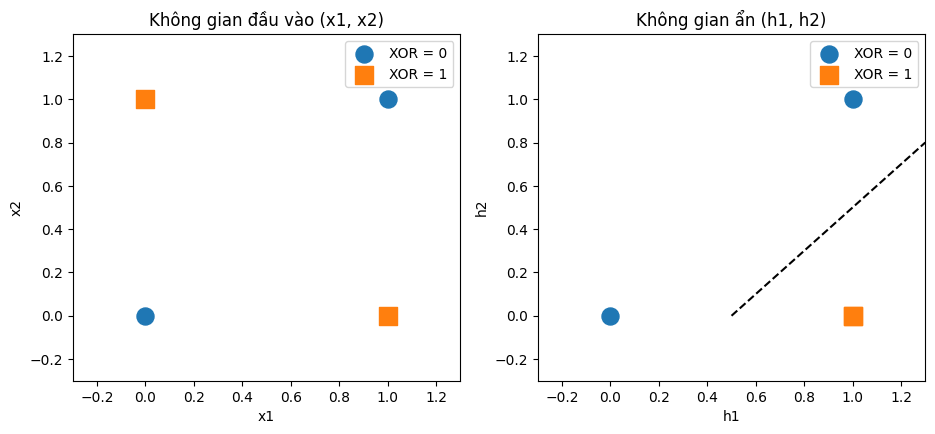

In [4]:
H = step(X @ W1.T + b1)                      # biểu diễn ẩn của cả 4 điểm (mỗi hàng một điểm)
print(H)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, data, title, labels in [(axes[0], X, 'Không gian đầu vào (x1, x2)', ('x1', 'x2')),
                                (axes[1], H, 'Không gian ẩn (h1, h2)', ('h1', 'h2'))]:
    ax.scatter(data[y == 0, 0], data[y == 0, 1], s=150, marker='o', label='XOR = 0')
    ax.scatter(data[y == 1, 0], data[y == 1, 1], s=150, marker='s', label='XOR = 1')
    ax.set_title(title); ax.set_xlabel(labels[0]); ax.set_ylabel(labels[1])
    ax.set_xlim(-0.3, 1.3); ax.set_ylim(-0.3, 1.3); ax.legend()
axes[1].plot([0.5, 1.3], [0, 0.8], 'k--')
plt.show()

## 4. Lan truyền xuôi dạng ma trận cho cả tập dữ liệu

Xếp $N$ mẫu thành các hàng của ma trận $\mathbf{X}$ ($N \times d$): $\mathbf{Z}^{(1)} = \mathbf{X}\mathbf{W}^{(1)T} + \mathbf{b}^{(1)}$, $\mathbf{A}^{(1)} = f(\mathbf{Z}^{(1)})$, …

In [5]:
A1 = step(X @ W1.T + b1)
A2 = step(A1 @ W2.T + b2)
print('Dự đoán:', A2.ravel().astype(int), ' nhãn:', y)

Dự đoán: [0 1 1 0]  nhãn: [0 1 1 0]
